# A racing drone that flies from its camera

Watch a first-person drone race and ask yourself what the pilot actually has to go on: a wide, rushing camera image, the body rates and rotor speeds the drone senses about itself, and a supplied flight plan that says where the next gates stand. From that, ninety times a second, the pilot chooses a thrust and three body rates, and threads gate after gate at speed.

Could a program learn to do that, starting from nothing, with nobody showing it how? In [tutorial 12](12-world-models.ipynb) we left a teacher that could race well because it was handed the privileged numbers directly: the drone's state, the gate corners and the obstacles. This tutorial takes those away. The pilot we train here reads its camera, the body rates and rotor speeds its own sensors report, and the supplied flight plan: the positions of the next three gates, from the track as laid out. Nothing else, at flight time. What it has instead is a world model, DreamerV3's, whose latent summary of the flight is trained to predict the very numbers the pilot is not allowed to read. To predict where the drone is, the latent has to contain where the drone is, and the policy learns to fly on that summary, rehearsing in the model's imagination as it goes.

![The pilot's loop, 90 times a second. The 64-pixel camera image, the body rates and rotor speeds the drone senses, and the supplied flight plan go into the world model's latent. The policy reads the latent and answers with a thrust and three body rates, and the quadrotor flies and moves the view. The privileged state below reaches the latent only as something to predict in training, never as something the policy reads. The camera picture is a frame recorded in this notebook.](https://raw.githubusercontent.com/AshishKumar4/dew/main/docs/assets/sky-loop.svg)

The recipe is SkyDreamer's ([Verraest et al., 2025](https://arxiv.org/abs/2510.14783)), and the race is its circle of gates, flown from a 64-pixel camera. The run below takes a million steps in the race, about two hours, and at the end the pilot passes 44.4 gates in an episode where the untrained policy passes none at all. The film at the end is it flying.


## Setup

You will want the GPU runtime. A ray tracer draws the cameras, so this notebook needs an NVIDIA GPU with OptiX, which Dew's `hyperlux` extra brings. The gates, ground and sky in those images are CC0 textures from Poly Haven, fetched and built into the renderer's assets by the second and third lines below.


In [1]:
%pip install -q "dewml[cuda13,hyperlux] @ git+https://github.com/AshishKumar4/dew@19860eb66b76325cf15a06fefcd6f51c1f55b018" --extra-index-url https://pypi.dewml.dev/simple
!curl -sLO https://raw.githubusercontent.com/AshishKumar4/dew/19860eb66b76325cf15a06fefcd6f51c1f55b018/tools/fpv_assets.py
!python fpv_assets.py assets > /dev/null

  Installing build dependencies ... done


  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import numpy as np

from dew import figures
from dew.rl.hyperlux import HyperLuxRenderer
from dew.rl.skydreamer import TRACKS, Sky, SkyDreamerRace

ASSETS = Path("assets")
print(jax.devices()[0])

cuda:0


## The race as the drone meets it

Let's meet the task the way the drone does, from inside, one step at a time. You wake up hovering at rest a few metres before a gate, a little off to one side, a little below its centre, your nose turned a bit away from it. The job sounds simple. Pass the gates in order, round the circle, again and again, as many as you can in 2000 steps before something ends the flight. At 90 steps a second that is about 22 seconds of air.

Your hands, so to speak, are four numbers between -1 and 1. The first is a throttle, where 0 asks for exactly the thrust that hovers, -1 for none and 1 for everything the motors have. The other three are body rates, how fast to pitch, roll and yaw, each as a share of this drone's rate limit. A flight controller under you turns those wishes into rotor speeds. There is no stick that says go left. To go left you roll, the thrust tilts, and the drone slides left while dropping a little unless you add thrust to pay for it. Every move is a small negotiation with gravity, which is why racing looks the way it does, all lean and swoop.

What are you scored on? Each gate is really three planes to cross in order: a pre-gate plane a little before the gate, the gate's own plane, and a post-gate plane just beyond it. SkyDreamer's reward then has three parts. Progress pays fivefold for closing on the next pre-gate plane, and only on that approach: from the pre-gate through the post-gate it pays nothing. Crossing any of the three planes pays a gate bonus of up to thirtyfold, scaled down the further from the gate's centre you cross, so one gate can pay that bonus three times. Against both sits a small cost on wild body rates, to keep the flying from turning into thrashing.

$$
r = 5 \cdot \text{progress} - \text{rate cost} + 30 \cdot \text{gate}
$$

An episode ends early in the ways you would hope it wouldn't. Cross any of a gate's three planes too far from its centre and you have missed it, flight over. Meet the ground while sinking fast or tipped well over, flight over. Otherwise you fly until the 2000 steps run out.

And what can you see? The camera image. Two short vectors the drone senses about itself: its body rates and its four rotor speeds. And one supplied vector, the flight plan, built from the track's known gate positions and headings: where the next three gates stand and which way they face. Held in the same observation, but not for the policy, is the privileged state, the drone's position, velocity and orientation, in the world and relative to the gate it is chasing. That state is the answer key. The world model will be trained to predict it. The policy will never lay eyes on it.

Let's start sixteen drones and look at what comes back.


{'image': (16, 64, 64, 3), 'rates': (16, 3), 'motors': (16, 4), 'plan': (16, 24), 'state': (16, 16), 'passed': (16,)}
tracks: ['circle', 'inverted_loop', 'ladder'] | action size 4


Figure(804 x 108, 1 shapes)
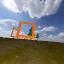
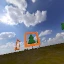
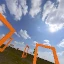
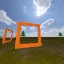
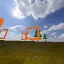
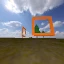
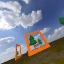
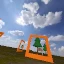

In [3]:
race = SkyDreamerRace(HyperLuxRenderer(16, ASSETS, size=64))
seen = race.reset(0)
print({name: tuple(value.shape) for name, value in seen.items()})
print("tracks:", list(TRACKS), "| action size", race.action_size)

# Eight drones' cameras at their starts, 64 x 64.
figures.images([np.asarray(seen["image"][:8])], columns=8, size=96)

There are the shapes to remember. An `image` of $64 \times 64$ for each of the 16 drones, `rates` with 3 numbers, `motors` with 4, a `plan` of 24, and the privileged `state` with 16, beside a count of gates `passed` that we will use for scoring. The first eight cameras are shown above at their starts. Everything the camera tells the pilot about the world has to come through a picture that size, alongside the sensed rates and rotor speeds and the supplied plan. Your phone would call it a thumbnail.

The race knows three tracks by name, a circle, an inverted loop and a ladder. This run races the circle, four gates standing on a ring, each episode drawn afresh on it. The other two are harder flights waiting for a longer run.

## A latent that has to know where it is

Now, how should a world model help here? Recall the shape from tutorial 12. The model keeps a latent in two parts, a deterministic memory $h$ and a drawn part $z$, and learns to predict rewards and next latents so the policy can rehearse inside it. Left to itself, though, a latent trained to rebuild camera images might spend itself on the look of the sky and the texture of the ground, things that fill pixels and matter not at all for flying. SkyDreamer's move is to change what the latent is asked to say.

Do not rebuild the image at all. Instead, from the latent alone, predict the privileged state, where the drone is, how fast it is going, which way it points, and also predict the body rates and rotor speeds it sensed. A latent that can answer those questions cannot be off daydreaming about clouds. It has to carry the geometry of the flight, squeezed out of a 64-pixel image, the sensed numbers and the plan, because that is the only way its predictions come true. SkyDreamer calls this an informed world model, and the picture below is the whole idea. The state flows in during training as a target to hit, and never at flight time as an input to read.

![What the latent learns to say. From the image, the sensed rates and rotor speeds and the supplied plan it must predict the privileged state and also the body rates and rotor speeds, while the image itself is not rebuilt at all. To predict the state, the latent must hold the state, and that is what the policy then flies from.](https://raw.githubusercontent.com/AshishKumar4/dew/main/docs/assets/sky-informed.svg)

Everything else in the run is in service of that one choice, but a few settings deserve a sentence each because you can feel what they are for. The model is DreamerV3's 12 million size: 12.9 million parameters as the run below draws it. Its $h$ is 2048 numbers wide and its $z$ 32 draws of 16 classes. It reads the image through convolutions and the other vectors through a small network beside them. The critic it rehearses against is a slow, averaged copy of itself, so the targets it chases do not jitter at every update. There is a small cost on how fast the policy's average action changes between imagined steps, SkyDreamer's smoothness term, because a real drone prefers intentions that do not flicker. And the replay is worked hard, which is where a world model earns its keep: training samples 128 replayed steps for every fresh race step, on average. Windows are drawn at random from what is stored, so no single step is replayed exactly 128 times. Real steps here mean ray traced images. They are the expensive part, so the run squeezes them.

Training also scores itself as it goes, on two sets of starts. One set, `evaluation`, always starts before the first gate, the arrangement SkyDreamer's Table III scores, with gate rewards counted over a wider area: 1 metre either side of a centre, where training allows 0.8. The other, `held_out`, draws starts the way training does, most of them before a gate anywhere round the track. Expect the first score to read higher; it is the tidier exam.

The next cell builds all of it in Python: the race, the networks, the objective, the replay, the optimizer and the two validations, each an object you could print or poke at.


In [ ]:
from dew.checkpoints import Checkpoints, Keep
from dew.config.env import idle
from dew.objectives.base import Shown
from dew.objectives.rl.dreamer import DreamerRollout, DreamerV3Objective, WorldModel
from dew.optim import Linear, OptimConfig
from dew.rl.evaluation import episodes
from dew.rl.simulator import DrivenSimulator
from dew.training import Episodes, EvalSuite, LocalTracker, Trainer

DRONES, EPISODE, STEPS, RUN_DIR = 16, 2000, 125_000, "runs/skydreamer"
race = SkyDreamerRace(HyperLuxRenderer(DRONES, ASSETS, size=64))
widths = {name: seen[name].shape[-1] for name in ("rates", "motors", "plan", "state")}

model = WorldModel(
    0, race.action_size, image=seen["image"].shape[1:], reads="image",
    proprio=tuple((name, widths[name]) for name in ("rates", "motors", "plan")),
    auxiliary=tuple((name, widths[name], 256) for name in ("state", "rates", "motors")),
    deter=2048, hidden=256, stoch=32, classes=16, blocks=8, units=256, conv_depth=16, dtype=jnp.bfloat16)
dreamer = DreamerV3Objective(model, slow_targets=True, smoothness=0.002, scales={"decoder": 0.0})
replay = DreamerRollout(dreamer, race, batch=16, length=64, train_ratio=128.0, capacity=2_000_000 // DRONES,
                        prefill=64)

def flown(sky):
    """A validation split: the greedy policy's first episode from each start of a race under `sky`."""
    judged = DrivenSimulator(SkyDreamerRace(HyperLuxRenderer(DRONES, ASSETS, size=64), sky))
    score = episodes(dreamer.greedy, judged, EPISODE, memory=dreamer.memory, reached=("passed",))
    return EvalSuite(Episodes(score, {"return": Shown(better="higher"), "steps": Shown(),
                                      "passed": Shown(better="higher")}))

validation = {"evaluation": flown(Sky(anywhere=0.0, size=1.0)), "held_out": flown(Sky())}
trainer = Trainer(dreamer, OptimConfig(optimizer="laprop", learning_rate=Linear(
                      peak_value=4e-5, warmup_steps=1000, end_value=4e-5)).build(STEPS),
                  key=jax.random.key(0), rollout=replay, checkpoints=Checkpoints(RUN_DIR, keep=Keep(latest=1)),
                  tracker=LocalTracker(f"{RUN_DIR}/tracking"))
print(f"{sum(np.size(leaf) for leaf in jax.tree.leaves(dreamer.init(jax.random.key(0)))) / 1e6:.1f}M parameters")

If the run is stopped part way, running the next cell again picks it up from its last checkpoint.

## Training for a million steps

Here it goes. 125,000 updates. Each update trains on sampled replay windows, paced at 128 replayed steps per fresh race step, so the arithmetic works out to 8 fresh race steps owed per update, a million steps in the race by the end. The losses are logged every 500 updates and both validations fly every 12,500. On the machine that ran this notebook, the whole thing took 110 minutes. Most of those minutes pay for rehearsing, update after update over replayed windows, rather than flying: precisely the trade a world model offers.


In [ ]:
began = time.perf_counter()
state = trainer.fit(idle(), steps=STEPS, log_every=500, eval_every=12_500, checkpoint_every=12_500,
                    validation=validation)
print(f"{int(state.step)} updates in {(time.perf_counter() - began) / 60:.0f} min")

By the last validation the run is reporting 44.31 gates from the evaluation starts and 40.88 from the held-out ones, with evaluation flights lasting the full 2000 steps. One thing those numbers cannot tell us is what the same flights would have scored before any training.

## The same flights, before and after

What would those same flights have earned before any training, with the networks as they were first drawn? If a fresh policy stumbles through a few gates by luck, some of our 44 is luck's. If the race hands out progress reward for merely drifting forwards, a return in the thousands might be less than it seems. A comparison on identical flights settles both questions: same starts, same gates, same drawn drones, one policy trained and one not, each judged on the first episode it flies from each start, so a long rollout full of restarts cannot pad the numbers.

That is what the next cell flies. One key deals the starts, both policies fly them greedily, taking their policy's average action with no exploring, and we read off each drone's first episode on both sets of starts.


In [ ]:
judged = {name: SkyDreamerRace(HyperLuxRenderer(DRONES, ASSETS, size=64), sky)
          for name, sky in (("evaluation", Sky(anywhere=0.0, size=1.0)), ("held_out", Sky()))}
for policy, variables in (("untrained", dreamer.init(jax.random.key(0))), ("trained", state.variables)):
    for name, judged_race in judged.items():
        score = episodes(dreamer.greedy, DrivenSimulator(judged_race), EPISODE, memory=dreamer.memory,
                         reached=("passed",))(variables, jax.random.key(7))
        print(f"{policy:>9} {name:>10}: {score['passed']:5.1f} gates, return {score['return']:7.1f}, "
              f"{score['steps']:6.0f} steps of {EPISODE}")

![The matched evaluation. One key deals the same starts to the untrained policy, as first drawn, and to the trained policy, and each of the 16 drones is scored on its first episode alone.](https://raw.githubusercontent.com/AshishKumar4/dew/main/docs/assets/sky-matched.svg)

The untrained policy passes no gates at all, on either set of starts, and its flights end early, 515 and 511 steps of the 2000, with returns below zero, -193.7 and -168.2. It does not even drift profitably. The trained policy, on the very same starts, passes 44.4 gates from the evaluation starts and flies every flight to the full 2000 steps for a return of 2723.7, and from the held-out starts it passes 36.2 gates in 1646 steps for 1859.8. Same drones, same gates, same first metres. The gap between those rows is the training.

Two notes on reading those numbers. The first is that the held-out number is lower, and flights there still end early on average, so starts drawn the training way, anywhere round the track, still catch it out more often. This is a pilot for one circular track, trained and scored in simulation, and its scores say nothing directly about a real drone in real wind. The second note is smaller but it will save you confusion in a moment. The training box reported 40.88 gates on held-out starts where this matched check says 36.2. The two checks flew different sampled flights, dealt from different keys, 16 first episodes each, so sampling variation alone can move either number by some gates. Neither estimate outranks the other: pairing the untrained policy on the same starts controls the before-and-after contrast, but it does not make 36.2 a more accurate estimate of the trained policy than 40.88.

## How the flying got there

The end state is only half the story; I always want to know what the middle looked like. The run logged every validation it flew, so we can just look. Each point below is one validation, the average over the 16 drones of their first episode, gates passed in the top chart and steps flown in the bottom one. The horizontal axis is real steps in the race, the update count times the 8 steps each update owes, so the right edge is our million.


In [7]:
from dew.training.tracker import LocalTracker

logged = LocalTracker("runs/skydreamer/tracking").scalars()
splits = ("evaluation", "held_out")
# Each update replays 16 windows of 64 steps, 128 for each environment step taken: 8 steps an update.
points = {name: [(step * 8, scalars) for step, scalars in logged if f"{name}/passed" in scalars]
          for name in splits}
steps = {name: [step for step, _ in points[name]] for name in splits}
display(figures.curve({name: [scalars[f"{name}/passed"] for _, scalars in points[name]] for name in splits},
                      x=steps, x_label="environment steps", y_label="gates passed in an episode"))
display(figures.curve({name: [scalars[f"{name}/steps"] for _, scalars in points[name]] for name in splits},
                      x=steps, x_label="environment steps", y_label="steps flown of 2000"))

Figure(460 x 290, 16 shapes)

Figure(460 x 290, 20 shapes)

Read the two charts together, because they explain each other. In the recorded curves, episode length rises before gate counts do. Early on, the gates chart sits near the floor while flights are still short, which fits a pilot whose episodes end before many gates can be reached. A drone that ends its flight at step 500 has at most 500 steps in which to find gates. Cross a gate's plane wide of the gate and the flight is over. Sink into the ground tipped over and the flight is over.

Once flights start lasting, the gate counts follow, and they keep climbing to the end of the run. The evaluation line ends on top in both charts, as we expected from its tidier starts, with its flights reaching the full 2000 steps while held-out flights still end early on average. The charts record only gates passed and steps flown, so they show that order and how far it got. They do not measure how near the centres the crossings were. Nothing in either curve suggests a single magic moment: a long floor, then a steady rise bought a few gates at a time, the way practice usually looks.

## Watching it fly

Numbers are convincing, but this is a flying thing and we have a camera, so let's watch. One problem first: the policy flies from $64 \times 64$ images, which are miserable to watch, and a film should show flights the policy actually flew rather than a fresh performance staged for the camera.

The trick is to run the race twice under the same actions. One race draws at 64 pixels and its images choose every action. A second race, started from the same seed so its drones wake in the same places on the same courses, draws at 256 pixels and takes the same action at every step, and the film is made from the large one's cameras. While an episode runs uninterrupted, both races step through the same physics under the same actions, so the film shows that episode through a cleaner window. The match is not unconditional: only the 64-pixel side sits in the driver that restarts a drone after its episode ends, and the filmed side is never restarted, so a drone whose episode ends would break the lockstep from that step on. The recorded film carries no termination flags, so read it as the pilot's own flights for as long as each episode runs, not as a guarantee across a restart.

![How the film is made. The 64-pixel race chooses each action from the images the policy flies from, and the 256-pixel race, started from the same seed, takes the same action at every step. While an episode runs uninterrupted the film shows that episode at a size worth watching; a restarted drone would break the match.](https://raw.githubusercontent.com/AshishKumar4/dew/main/docs/assets/sky-twin.svg)

Four drones this time, for 1800 steps, laid side by side into one film at 90 frames a second, the rate the race itself runs at.


In [8]:
import imageio.v2 as imageio
from IPython.display import Video

from dew.rl.env import view
from dew.rl.simulator import simulator_start

FILMED = 4
flying = DrivenSimulator(SkyDreamerRace(HyperLuxRenderer(FILMED, ASSETS, size=64), Sky(anywhere=0.0)))
filmed = SkyDreamerRace(HyperLuxRenderer(FILMED, ASSETS, size=256), Sky(anywhere=0.0))
key = jax.random.key(11)
carry = simulator_start(flying, key, dreamer.memory(FILMED))
seed_key, _ = jax.random.split(key)
filmed.reset(int(jax.random.randint(seed_key, (), 0, jnp.iinfo(jnp.int32).max)))
step, memory, frames = carry.observation, carry.memory, []
for t in range(1800):
    action, _, memory = dreamer.greedy(state.variables, step, jax.random.fold_in(key, t), memory)
    step = flying.step(action).observation
    frames.append(np.concatenate(list(np.asarray(view(filmed.step(action).observation, "image"))), 1))
imageio.mimwrite("pilot.mp4", frames, fps=90, macro_block_size=1)
Video("pilot.mp4", embed=True, width=1024)

/usr/lib/python3.13/subprocess.py:1922: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


Where would you push it next? The race already knows its harder tracks, the inverted loop and the ladder, with gates you fly over rather than through and manoeuvres no circular run will teach, and its starts, drones and cameras can all be randomised harder as a curriculum, the way the gate racing in [tutorial 12](12-world-models.ipynb) ramps its difficulty. Each of those asks for a longer run than this one, and the record you saved above is exactly where you would write it down. Change the track, raise the steps, and the same `dew train` command flies it.
